In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("../data/raw/fake_job_postings.csv")

# Display first 5 records
df.head()

,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent,in_balanced_dataset
0,Marketing Intern,"US, NY, New York",Marketing,NaN,"<h3>We're Food52, and we've created a groundbr...","<p>Food52, a fast-growing, James Beard Award-w...",<ul>\r\n<li>Experience with content management...,NaN,f,t,f,Other,Internship,NaN,NaN,Marketing,f,f
1,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"<h3>90 Seconds, the worlds Cloud Video Product...",<p>Organised - Focused - Vibrant - Awesome!<br...,<p><b>What we expect from you:</b></p>\r\n<p>Y...,<h3><b>What you will get from us</b></h3>\r\n<...,f,t,f,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,f,f
2,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,<h3></h3>\r\n<p>Valor Services provides Workfo...,"<p>Our client, located in Houston, is actively...",<ul>\r\n<li>Implement pre-commissioning and co...,NaN,f,t,f,NaN,NaN,NaN,NaN,NaN,f,f
3,Account Executive - Washington DC,"US, DC, Washington",Sales,NaN,<p>Our passion for improving quality of life t...,<p><b>THE COMPANY: ESRI – Environmental System...,<ul>\r\n<li>\r\n<b>EDUCATION: </b>Bachelor’s o...,<p>Our culture is anything but corporate—we ha...,f,t,f,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Sales,f,f
4,Bill Review Manager,"US, FL, Fort Worth",NaN,NaN,<p>SpotSource Solutions LLC is a Global Human ...,<p><b>JOB TITLE:</b> Itemization Review Manage...,<p><b>QUALIFICATIONS:</b></p>\r\n<ul>\r\n<li>R...,<p>Full Benefits Offered</p>,f,t,t,Full-time,Mid-Senior level,Bachelor's Degree,Hospital & Health Care,Health Care Provider,f,f


In [2]:
print("Dataset Shape:", df.shape)
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

Dataset Shape: (17880, 18)
Total Rows: 17880
Total Columns: 18


In [3]:
print("Dataset Columns:")

for col in df.columns:
    print(col)

Dataset Columns:
title
location
department
salary_range
company_profile
description
requirements
benefits
telecommuting
has_company_logo
has_questions
employment_type
required_experience
required_education
industry
function
fraudulent
in_balanced_dataset


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17880 entries, 0 to 17879
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   title                17880 non-null  str  
 1   location             17534 non-null  str  
 2   department           6333 non-null   str  
 3   salary_range         2868 non-null   str  
 4   company_profile      14572 non-null  str  
 5   description          17880 non-null  str  
 6   requirements         15191 non-null  str  
 7   benefits             10684 non-null  str  
 8   telecommuting        17880 non-null  str  
 9   has_company_logo     17880 non-null  str  
 10  has_questions        17880 non-null  str  
 11  employment_type      14409 non-null  str  
 12  required_experience  10830 non-null  str  
 13  required_education   9775 non-null   str  
 14  industry             12977 non-null  str  
 15  function             11425 non-null  str  
 16  fraudulent           17880 non-nu

In [5]:
missing_values = df.isnull().sum()

print(missing_values[missing_values > 0].sort_values(ascending=False))

salary_range           15012
department             11547
required_education      8105
benefits                7196
required_experience     7050
function                6455
industry                4903
employment_type         3471
company_profile         3308
requirements            2689
location                 346
dtype: int64


In [6]:
print(df['fraudulent'].value_counts(dropna=False))

fraudulent
f    17014
t      866
Name: count, dtype: int64


In [7]:
print(
    df['fraudulent']
    .value_counts(normalize=True, dropna=False) * 100
)

fraudulent
f    95.1566
t     4.8434
Name: proportion, dtype: float64


In [8]:
print(df['in_balanced_dataset'].value_counts(dropna=False))

in_balanced_dataset
f    16980
t      900
Name: count, dtype: int64


In [9]:
display(df[['title', 'fraudulent', 'in_balanced_dataset']].head(10))

,title,fraudulent,in_balanced_dataset
0,Marketing Intern,f,f
1,Customer Service - Cloud Video Production,f,f
2,Commissioning Machinery Assistant (CMA),f,f
3,Account Executive - Washington DC,f,f
4,Bill Review Manager,f,f
5,Accounting Clerk,f,f
6,Head of Content (m/f),f,f
7,Lead Guest Service Specialist,f,f
8,HP BSM SME,f,f
9,Customer Service Associate - Part Time,f,f


In [10]:
print(df['in_balanced_dataset'].value_counts(dropna=False))

print(pd.crosstab(
    df['in_balanced_dataset'],
    df['fraudulent']
))

in_balanced_dataset
f    16980
t      900
Name: count, dtype: int64
fraudulent               f    t
in_balanced_dataset            
f                    16564  416
t                      450  450


In [11]:
# Check completely duplicated rows
print("Total duplicate rows:", df.duplicated().sum())

Total duplicate rows: 235


In [12]:
print(
    "Duplicate descriptions:",
    df['description'].duplicated().sum()
)

Duplicate descriptions: 2785


In [13]:
print("Fraudulent unique values:")
print(df['fraudulent'].unique())

print("\nBalanced dataset unique values:")
print(df['in_balanced_dataset'].unique())

print("\nMissing target values:")
print(df['fraudulent'].isnull().sum())

Fraudulent unique values:
<StringArray>
['f', 't']
Length: 2, dtype: str

Balanced dataset unique values:
<StringArray>
['f', 't']
Length: 2, dtype: str

Missing target values:
0


In [14]:
# Find descriptions associated with multiple fraud labels

description_label_counts = (
    df.groupby('description')['fraudulent']
    .nunique()
)

conflicting_descriptions = description_label_counts[
    description_label_counts > 1
]

print("Descriptions with conflicting labels:",
      len(conflicting_descriptions))

Descriptions with conflicting labels: 1


In [15]:
if len(conflicting_descriptions) > 0:

    sample_descriptions = conflicting_descriptions.index[:5]

    display(
        df[df['description'].isin(sample_descriptions)][
            ['title', 'description', 'fraudulent']
        ]
    )
else:
    print("No conflicting descriptions found.")

,title,description,fraudulent
9138,Front-End/JavaScript Engineer,<p>Workable is a product-driven software compa...,t
11889,Developer (Front-end team),<p>Workable is a product-driven software compa...,f
15236,Developer,<p>Workable is a product-driven software compa...,f


In [16]:
conflict_rows = df.loc[[9138, 11889, 15236]]

columns_to_compare = [
    'title',
    'location',
    'department',
    'salary_range',
    'company_profile',
    'employment_type',
    'required_experience',
    'industry',
    'function',
    'fraudulent'
]

display(conflict_rows[columns_to_compare].T)

,9138,11889,15236
title,Front-End/JavaScript Engineer,Developer (Front-end team),Developer
location,"ID, JW, Jakarta","GR, I, Athens","GR, I, Athens"
department,Frontend,Engineering,Engineering
salary_range,NaN,NaN,NaN
company_profile,NaN,<p>Workable is a venture-backed startup making...,<p>Workable is a venture-backed startup making...
employment_type,NaN,Full-time,Full-time
required_experience,NaN,Not Applicable,Not Applicable
industry,NaN,Computer Software,Computer Software
function,NaN,Engineering,Engineering
fraudulent,t,f,f


In [17]:
# Create a cleaned copy of the dataset
df_clean = df.drop_duplicates().copy()

# Check how many records were removed
print("Original dataset shape:", df.shape)
print("After removing duplicates:", df_clean.shape)

print("Duplicate rows remaining:", df_clean.duplicated().sum())

Original dataset shape: (17880, 18)
After removing duplicates: (17645, 18)
Duplicate rows remaining: 0


In [18]:
# Convert target labels into numerical values

df_clean['fraudulent'] = df_clean['fraudulent'].map({
    'f': 0,
    't': 1
})

# Verify conversion
print(df_clean['fraudulent'].value_counts())

print("\nData type:")
print(df_clean['fraudulent'].dtype)

print("\nMissing target values:")
print(df_clean['fraudulent'].isnull().sum())

fraudulent
0    16787
1      858
Name: count, dtype: int64

Data type:
int64

Missing target values:
0


In [19]:
# Calculate missing values
missing_count = df_clean.isnull().sum()

# Calculate missing percentage
missing_percentage = (
    df_clean.isnull().mean() * 100
).round(2)

# Create summary table
missing_summary = pd.DataFrame({
    'Missing Count': missing_count,
    'Missing Percentage': missing_percentage
})

# Display only columns with missing values
missing_summary = missing_summary[
    missing_summary['Missing Count'] > 0
].sort_values(by='Missing Percentage', ascending=False)

display(missing_summary)

,Missing Count,Missing Percentage
salary_range,14813,83.95
department,11362,64.39
required_education,8028,45.50
benefits,7103,40.26
required_experience,6976,39.54
function,6378,36.15
industry,4849,27.48
employment_type,3435,19.47
company_profile,3287,18.63
requirements,2650,15.02


In [20]:
# Create a separate working dataset
df_processed = df_clean.copy()

# Text columns
text_columns = [
    'company_profile',
    'description',
    'requirements',
    'benefits'
]

# Categorical columns
categorical_columns = [
    'title',
    'location',
    'department',
    'salary_range',
    'employment_type',
    'required_experience',
    'required_education',
    'industry',
    'function'
]

# Fill missing text with empty strings
for col in text_columns:
    df_processed[col] = df_processed[col].fillna('')

# Fill missing categorical values
for col in categorical_columns:
    df_processed[col] = df_processed[col].fillna('Not Provided')

print("Remaining missing values:")
print(df_processed.isnull().sum().sum())

Remaining missing values:
0


In [21]:
binary_columns = [
    'telecommuting',
    'has_company_logo',
    'has_questions'
]

for col in binary_columns:
    print(f"\n{col}:")
    print(df_processed[col].value_counts(dropna=False))


telecommuting:
telecommuting
f    16889
t      756
Name: count, dtype: int64

has_company_logo:
has_company_logo
t    14011
f     3634
Name: count, dtype: int64

has_questions:
has_questions
f    8969
t    8676
Name: count, dtype: int64


In [22]:
# Convert binary columns into numerical values

binary_columns = [
    'telecommuting',
    'has_company_logo',
    'has_questions'
]

for col in binary_columns:
    df_processed[col] = df_processed[col].map({
        'f': 0,
        't': 1
    })

# Verify conversion
print(df_processed[binary_columns].head())

print("\nData types:")
print(df_processed[binary_columns].dtypes)

print("\nMissing values after conversion:")
print(df_processed[binary_columns].isnull().sum())

   telecommuting  has_company_logo  has_questions
0              0                 1              0
1              0                 1              0
2              0                 1              0
3              0                 1              0
4              0                 1              1

Data types:
telecommuting       int64
has_company_logo    int64
has_questions       int64
dtype: object

Missing values after conversion:
telecommuting       0
has_company_logo    0
has_questions       0
dtype: int64


In [23]:
categorical_columns = [
    'title',
    'location',
    'department',
    'salary_range',
    'employment_type',
    'required_experience',
    'required_education',
    'industry',
    'function'
]

for col in categorical_columns:
    print(f"{col}: {df_processed[col].nunique()} unique values")

title: 11231 unique values
location: 3106 unique values
department: 1338 unique values
salary_range: 875 unique values
employment_type: 6 unique values
required_experience: 8 unique values
required_education: 14 unique values
industry: 132 unique values
function: 38 unique values


In [24]:
# Text columns
text_columns = [
    'company_profile',
    'description',
    'requirements',
    'benefits'
]

# Calculate text length
for col in text_columns:
    df_processed[col + '_length'] = (
        df_processed[col].astype(str).str.len()
    )

# Display statistics
display(
    df_processed[
        [col + '_length' for col in text_columns]
    ].describe().round(2)
)

,company_profile_length,description_length,requirements_length,benefits_length
count,17645.00,17645.00,17645.00,17645.00
mean,692.76,1439.34,732.92,267.88
std,649.70,1723.07,1260.30,668.94
min,0.00,10.00,0.00,0.00
25%,150.00,674.00,183.00,0.00
50%,613.00,1157.00,565.00,62.00
75%,966.00,1776.00,971.00,360.00
max,6450.00,55130.00,37994.00,19455.00


In [25]:
for col in text_columns:
    print(f"\n{'='*60}")
    print(f"COLUMN: {col}")
    print(f"{'='*60}")

    print(df_processed[col].iloc[0][:500])


COLUMN: company_profile
<h3>We're Food52, and we've created a groundbreaking and award-winning cooking site. We support, connect, and celebrate home cooks, and give them everything they need in one place.</h3>
<p>We have a top editorial, business, and engineering team. We're focused on using technology to find new and better ways to connect people around their specific food interests, and to offer them superb, highly curated information about food and cooking. We attract the most talented home cooks and contributors i

COLUMN: description
<p>Food52, a fast-growing, James Beard Award-winning online food community and crowd-sourced and curated recipe hub, is currently interviewing full- and part-time unpaid interns to work in a small team of editors, executives, and developers in its New York City headquarters.</p>
<ul>
<li>Reproducing and/or repackaging existing Food52 content for a number of partner sites, such as Huffington Post, Yahoo, Buzzfeed, and more in their various content man

In [26]:
print("Final shape:", df_processed.shape)

print("Total missing values:",
      df_processed.isnull().sum().sum())

print("\nData types:")
print(df_processed.dtypes)

Final shape: (17645, 22)
Total missing values: 0

Data types:
title                       str
location                    str
department                  str
salary_range                str
company_profile             str
description                 str
requirements                str
benefits                    str
telecommuting             int64
has_company_logo          int64
has_questions             int64
employment_type             str
required_experience         str
required_education          str
industry                    str
function                    str
fraudulent                int64
in_balanced_dataset         str
company_profile_length    int64
description_length        int64
requirements_length       int64
benefits_length           int64
dtype: object


In [27]:
from bs4 import BeautifulSoup
import re

text_columns = [
    'company_profile',
    'description',
    'requirements',
    'benefits'
]

for col in text_columns:
    df_processed[col + '_clean'] = (
        df_processed[col]
        .apply(lambda x: BeautifulSoup(str(x), 'html.parser').get_text(separator=' '))
        .str.replace(r'\s+', ' ', regex=True)
        .str.strip()
    )
    

In [28]:
print("ORIGINAL TEXT:")
print(df_processed['description'].iloc[0][:300])

print("\nCLEANED TEXT:")
print(df_processed['description_clean'].iloc[0][:300])

ORIGINAL TEXT:
<p>Food52, a fast-growing, James Beard Award-winning online food community and crowd-sourced and curated recipe hub, is currently interviewing full- and part-time unpaid interns to work in a small team of editors, executives, and developers in its New York City headquarters.</p>
<ul>
<li>Reproduci

CLEANED TEXT:
Food52, a fast-growing, James Beard Award-winning online food community and crowd-sourced and curated recipe hub, is currently interviewing full- and part-time unpaid interns to work in a small team of editors, executives, and developers in its New York City headquarters. Reproducing and/or repackag


In [29]:
print("Dataset shape:", df_processed.shape)

print("\nMissing values:", df_processed.isnull().sum().sum())

print("\nCleaned text columns:")
for col in text_columns:
    print(col + '_clean')

Dataset shape: (17645, 26)

Missing values: 0

Cleaned text columns:
company_profile_clean
description_clean
requirements_clean
benefits_clean


Legitimate Jobs: 16787
Fraudulent Jobs: 858


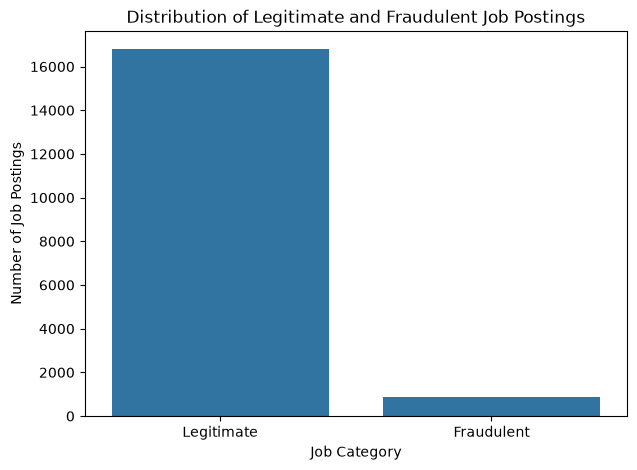

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count legitimate and fraudulent jobs
fraud_counts = df_processed['fraudulent'].value_counts().sort_index()

print("Legitimate Jobs:", fraud_counts[0])
print("Fraudulent Jobs:", fraud_counts[1])

# Plot distribution
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df_processed,
    x='fraudulent'
)

plt.xticks(
    [0, 1],
    ['Legitimate', 'Fraudulent']
)

plt.title('Distribution of Legitimate and Fraudulent Job Postings')
plt.xlabel('Job Category')
plt.ylabel('Number of Job Postings')

plt.show()

In [31]:
length_columns = [
    'company_profile_clean',
    'description_clean',
    'requirements_clean',
    'benefits_clean'
]

# Calculate text lengths
for col in length_columns:
    df_processed[col + '_length'] = (
        df_processed[col].str.len()
    )

# Compare average text lengths
comparison = df_processed.groupby('fraudulent')[
    [col + '_length' for col in length_columns]
].mean().round(2)

comparison.index = ['Legitimate', 'Fraudulent']

comparison

,company_profile_clean_length,description_clean_length,requirements_clean_length,benefits_clean_length
Legitimate,639.75,1212.99,599.98,208.62
Fraudulent,229.47,1152.99,449.52,211.44


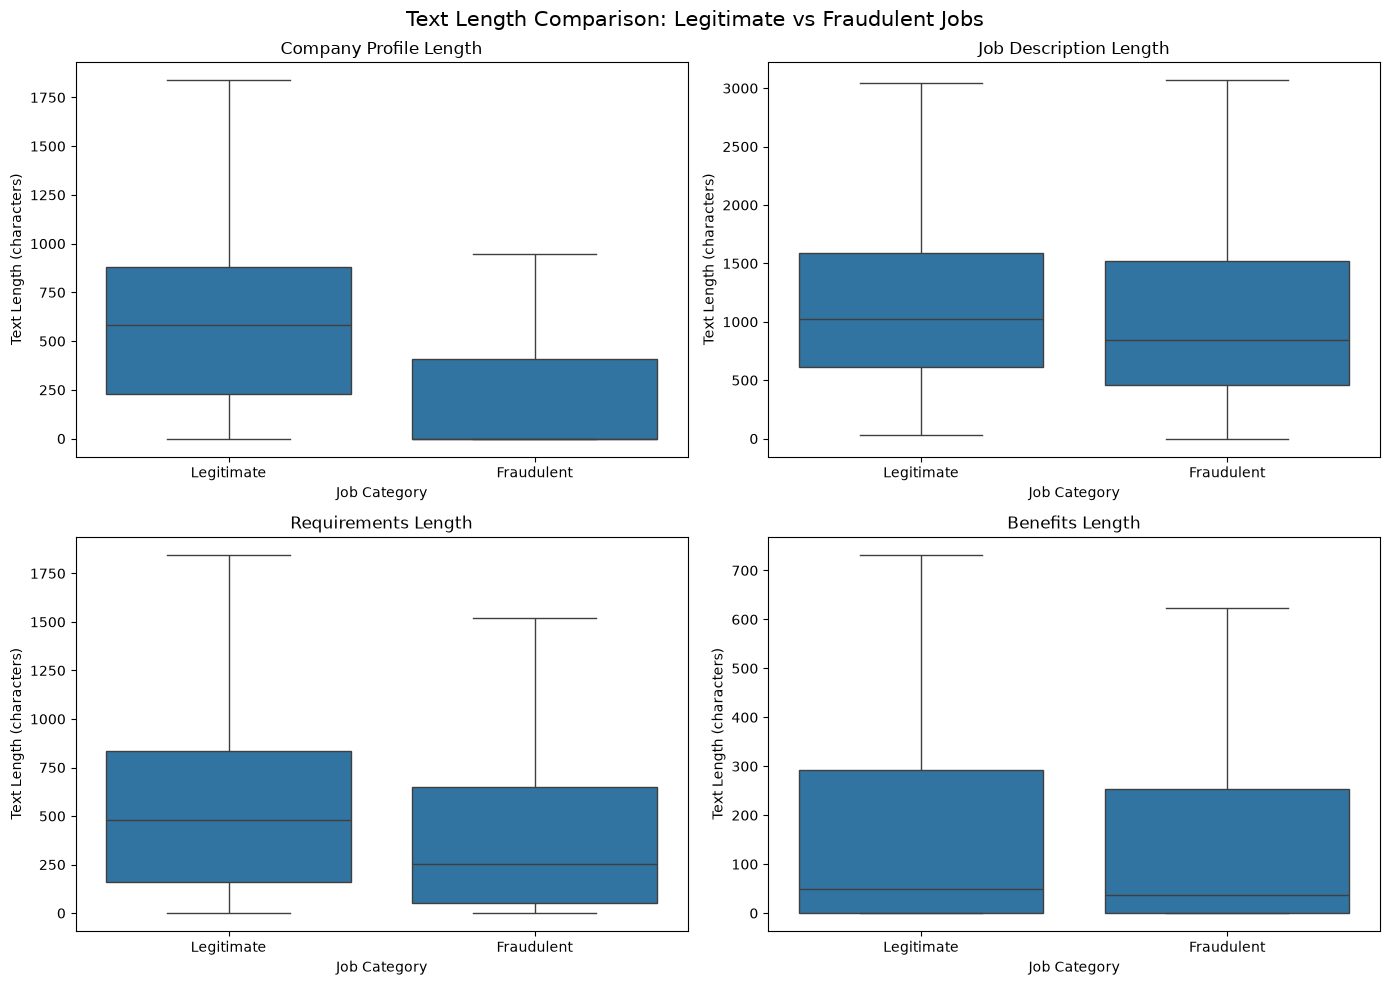

In [32]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

length_columns = [
    'company_profile_clean_length',
    'description_clean_length',
    'requirements_clean_length',
    'benefits_clean_length'
]

titles = [
    'Company Profile Length',
    'Job Description Length',
    'Requirements Length',
    'Benefits Length'
]

for ax, col, title in zip(
    axes.flatten(), length_columns, titles
):
    sns.boxplot(
        data=df_processed,
        x='fraudulent',
        y=col,
        showfliers=False,
        ax=ax
    )

    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Legitimate', 'Fraudulent'])
    ax.set_title(title)
    ax.set_xlabel('Job Category')
    ax.set_ylabel('Text Length (characters)')

plt.suptitle(
    'Text Length Comparison: Legitimate vs Fraudulent Jobs',
    fontsize=15
)

plt.tight_layout()
plt.show()

In [33]:
employment_analysis = pd.crosstab(
    df_processed['employment_type'],
    df_processed['fraudulent']
)

employment_analysis.columns = [
    'Legitimate',
    'Fraudulent'
]

employment_analysis['Fraud_Percentage'] = (
    employment_analysis['Fraudulent'] /
    (
        employment_analysis['Legitimate'] +
        employment_analysis['Fraudulent']
    )
) * 100

employment_analysis.sort_values(
    by='Fraud_Percentage',
    ascending=False
).round(2)

,Legitimate,Fraudulent,Fraud_Percentage
employment_type,,,
Part-time,701,73,9.43
Not Provided,3199,236,6.87
Other,210,15,6.67
Full-time,10969,488,4.26
Contract,1473,44,2.90
Temporary,235,2,0.84


In [34]:
experience_analysis = pd.crosstab(
    df_processed['required_experience'],
    df_processed['fraudulent']
)

experience_analysis.columns = [
    'Legitimate',
    'Fraudulent'
]

experience_analysis['Total'] = (
    experience_analysis['Legitimate'] +
    experience_analysis['Fraudulent']
)

experience_analysis['Fraud_Percentage'] = (
    experience_analysis['Fraudulent'] /
    experience_analysis['Total']
) * 100

experience_analysis.sort_values(
    by='Fraud_Percentage',
    ascending=False
).round(2)

,Legitimate,Fraudulent,Total,Fraud_Percentage
required_experience,,,,
Executive,130,10,140,7.14
Entry level,2467,178,2645,6.73
Not Provided,6548,428,6976,6.14
Not Applicable,1017,60,1077,5.57
Director,368,17,385,4.42
Mid-Senior level,3661,113,3774,2.99
Internship,364,10,374,2.67
Associate,2232,42,2274,1.85


In [35]:
education_analysis = pd.crosstab(
    df_processed['required_education'],
    df_processed['fraudulent']
)

education_analysis.columns = [
    'Legitimate',
    'Fraudulent'
]

education_analysis['Total'] = (
    education_analysis['Legitimate'] +
    education_analysis['Fraudulent']
)

education_analysis['Fraud_Percentage'] = (
    education_analysis['Fraudulent'] /
    education_analysis['Total']
) * 100

education_analysis.sort_values(
    by='Fraud_Percentage',
    ascending=False
).round(2)

,Legitimate,Fraudulent,Total,Fraud_Percentage
required_education,,,,
Some High School Coursework,7,20,27,74.07
Certification,146,19,165,11.52
High School or equivalent,1833,169,2002,8.44
Master's Degree,385,31,416,7.45
Not Provided,7583,445,8028,5.54
Professional,69,4,73,5.48
Unspecified,1314,61,1375,4.44
Doctorate,25,1,26,3.85
Some College Coursework Completed,97,3,100,3.00


In [36]:
industry_analysis = pd.crosstab(
    df_processed['industry'],
    df_processed['fraudulent']
)

industry_analysis.columns = [
    'Legitimate',
    'Fraudulent'
]

industry_analysis['Total'] = (
    industry_analysis['Legitimate'] +
    industry_analysis['Fraudulent']
)

industry_analysis['Fraud_Percentage'] = (
    industry_analysis['Fraudulent'] /
    industry_analysis['Total']
) * 100

# Consider industries having at least 30 records
industry_analysis = industry_analysis[
    industry_analysis['Total'] >= 30
]

industry_analysis.sort_values(
    by='Fraud_Percentage',
    ascending=False
).round(2).head(15)

,Legitimate,Fraudulent,Total,Fraud_Percentage
industry,,,,
Oil & Energy,178,108,286,37.76
Accounting,102,57,159,35.85
"Leisure, Travel & Tourism",52,20,72,27.78
Computer Networking,32,12,44,27.27
Hospitality,74,14,88,15.91
Real Estate,143,24,167,14.37
"Health, Wellness and Fitness",108,15,123,12.20
Mechanical or Industrial Engineering,33,4,37,10.81
Biotechnology,34,4,38,10.53


In [37]:
binary_features = [
    'has_company_logo',
    'has_questions',
    'telecommuting'
]

for feature in binary_features:

    analysis = pd.crosstab(
        df_processed[feature],
        df_processed['fraudulent']
    )

    analysis.columns = ['Legitimate', 'Fraudulent']

    analysis['Total'] = (
        analysis['Legitimate'] + analysis['Fraudulent']
    )

    analysis['Fraud_Percentage'] = (
        analysis['Fraudulent'] / analysis['Total']
    ) * 100

    analysis.index = [
        'No' if value == 0 else 'Yes'
        for value in analysis.index
    ]

    print(f"\n{feature.upper()} ANALYSIS")
    print(analysis.round(2))


HAS_COMPANY_LOGO ANALYSIS
     Legitimate  Fraudulent  Total  Fraud_Percentage
No         3058         576   3634             15.85
Yes       13729         282  14011              2.01

HAS_QUESTIONS ANALYSIS
     Legitimate  Fraudulent  Total  Fraud_Percentage
No         8360         609   8969              6.79
Yes        8427         249   8676              2.87

TELECOMMUTING ANALYSIS
     Legitimate  Fraudulent  Total  Fraud_Percentage
No        16095         794  16889              4.70
Yes         692          64    756              8.47


In [38]:
clean_text_columns = [
    'company_profile_clean',
    'description_clean',
    'requirements_clean',
    'benefits_clean'
]

# Calculate length of cleaned text
for col in clean_text_columns:
    df_processed[col + '_length'] = (
        df_processed[col].str.len()
    )

# Verify
print("Dataset shape:", df_processed.shape)

print("\nCleaned text lengths:")
print(
    df_processed[
        [col + '_length' for col in clean_text_columns]
    ].describe().round(2)
)

print("\nMissing values:",
      df_processed.isnull().sum().sum())

Dataset shape: (17645, 30)

Cleaned text lengths:
       company_profile_clean_length  description_clean_length  \
count                       17645.0                  17645.00   
mean                          619.8                   1210.07   
std                           568.0                    867.86   
min                             0.0                      0.00   
25%                           135.0                    602.00   
50%                           560.0                   1017.00   
75%                           875.0                   1582.00   
max                          6150.0                  14810.00   

       requirements_clean_length  benefits_clean_length  
count                   17645.00               17645.00  
mean                      592.66                 208.76  
std                       612.63                 336.03  
min                         0.00                   0.00  
25%                       150.00                   0.00  
50%             

In [39]:
# 1. Define categorical features
categorical_features = [
    'title',
    'location',
    'department',
    'salary_range',
    'employment_type',
    'required_experience',
    'required_education',
    'industry',
    'function'
]

# 2. Define numerical features
numerical_features = [
    'telecommuting',
    'has_company_logo',
    'has_questions',
    'company_profile_clean_length',
    'description_clean_length',
    'requirements_clean_length',
    'benefits_clean_length'
]

# 3. Combine model features
feature_columns = categorical_features + numerical_features

# 4. Create X and y
X = df_processed[feature_columns].copy()
y = df_processed['fraudulent'].copy()

# 5. Verify
print("Input features shape:", X.shape)
print("Target shape:", y.shape)

print("\nCategorical features:")
print(categorical_features)

print("\nNumerical features:")
print(numerical_features)

print("\nTarget distribution:")
print(y.value_counts())

print("\nMetadata excluded:", 'in_balanced_dataset' not in X.columns)
print("Cleaned text kept separately:",
      all(col in df_processed.columns for col in clean_text_columns))

Input features shape: (17645, 16)
Target shape: (17645,)

Categorical features:
['title', 'location', 'department', 'salary_range', 'employment_type', 'required_experience', 'required_education', 'industry', 'function']

Numerical features:
['telecommuting', 'has_company_logo', 'has_questions', 'company_profile_clean_length', 'description_clean_length', 'requirements_clean_length', 'benefits_clean_length']

Target distribution:
fraudulent
0    16787
1      858
Name: count, dtype: int64

Metadata excluded: True
Cleaned text kept separately: True


In [40]:
from sklearn.model_selection import train_test_split

# Split features and target
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Keep corresponding cleaned text data separate
X_text_train = df_processed.loc[
    X_train.index, clean_text_columns
].copy()

X_text_test = df_processed.loc[
    X_test.index, clean_text_columns
].copy()

# Check dataset sizes
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target:", y_train.shape)
print("Testing Target:", y_test.shape)

print("\nTraining Distribution:")
print(y_train.value_counts())

print("\nTesting Distribution:")
print(y_test.value_counts())

print("\nFraud percentage:")
print("Training:", round(y_train.mean() * 100, 2), "%")
print("Testing:", round(y_test.mean() * 100, 2), "%")

Training Features: (14116, 16)
Testing Features: (3529, 16)

Training Target: (14116,)
Testing Target: (3529,)

Training Distribution:
fraudulent
0    13430
1      686
Name: count, dtype: int64

Testing Distribution:
fraudulent
0    3357
1     172
Name: count, dtype: int64

Fraud percentage:
Training: 4.86 %
Testing: 4.87 %


In [41]:
from sklearn.model_selection import train_test_split

# Split training data into training and validation
X_train_final, X_valid, y_train_final, y_valid = train_test_split(
    X_train,
    y_train,
    test_size=0.15,
    random_state=42,
    stratify=y_train
)

print("Final Training Shape:", X_train_final.shape)
print("Validation Shape:", X_valid.shape)

print("\nFinal Training Distribution:")
print(y_train_final.value_counts())

print("\nValidation Distribution:")
print(y_valid.value_counts())

Final Training Shape: (11998, 16)
Validation Shape: (2118, 16)

Final Training Distribution:
fraudulent
0    11415
1      583
Name: count, dtype: int64

Validation Distribution:
fraudulent
0    2015
1     103
Name: count, dtype: int64


In [42]:
# Create copies for CatBoost
X_train_cb = X_train_final.copy()
X_valid_cb = X_valid.copy()

# Ensure categorical columns are strings
for col in categorical_features:
    X_train_cb[col] = X_train_cb[col].astype(str)
    X_valid_cb[col] = X_valid_cb[col].astype(str)

print("Training data ready:", X_train_cb.shape)
print("Validation data ready:", X_valid_cb.shape)

print("\nCategorical data types:")
print(X_train_cb[categorical_features].dtypes)

Training data ready: (11998, 16)
Validation data ready: (2118, 16)

Categorical data types:
title                  str
location               str
department             str
salary_range           str
employment_type        str
required_experience    str
required_education     str
industry               str
function               str
dtype: object


In [43]:
from catboost import CatBoostClassifier

# Initialize model
cat_model = CatBoostClassifier(
    iterations=1500,
    learning_rate=0.05,
    depth=6,
    loss_function='Logloss',
    eval_metric='AUC',
    auto_class_weights='Balanced',
    random_seed=42,
    verbose=100,
    allow_writing_files=False
)

# Train model
cat_model.fit(
    X_train_cb,
    y_train_final,
    cat_features=categorical_features,
    eval_set=(X_valid_cb, y_valid),
    early_stopping_rounds=100,
    verbose=100
)

0:	test: 0.8540533	best: 0.8540533 (0)	total: 213ms	remaining: 5m 19s
100:	test: 0.9648992	best: 0.9648992 (100)	total: 7.11s	remaining: 1m 38s
200:	test: 0.9702763	best: 0.9702763 (200)	total: 13.5s	remaining: 1m 27s
300:	test: 0.9717555	best: 0.9724783 (247)	total: 18.5s	remaining: 1m 13s
400:	test: 0.9732444	best: 0.9733214 (394)	total: 24s	remaining: 1m 5s
500:	test: 0.9737503	best: 0.9737503 (500)	total: 29.4s	remaining: 58.7s
600:	test: 0.9728878	best: 0.9739334 (512)	total: 36s	remaining: 53.9s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.9739333638
bestIteration = 512

Shrink model to first 513 iterations.


CatBoostClassifier(allow_writing_files=False, auto_class_weights='Balanced', depth=6, eval_metric='AUC', iterations=1500, learning_rate=0.05, loss_function='Logloss', random_seed=42, verbose=100)

CLASSIFICATION REPORT
              precision    recall  f1-score   support

  Legitimate       0.99      0.98      0.99      2015
  Fraudulent       0.71      0.83      0.77       103

    accuracy                           0.98      2118
   macro avg       0.85      0.90      0.88      2118
weighted avg       0.98      0.98      0.98      2118


CONFUSION MATRIX
[[1981   34]
 [  18   85]]

ROC-AUC: 0.9739
PR-AUC: 0.8684


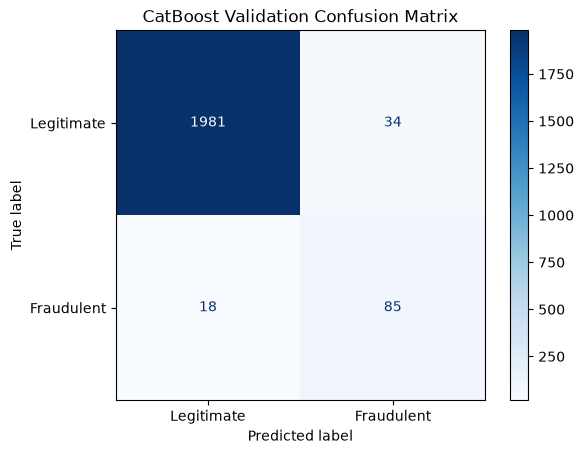

In [44]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    average_precision_score
)
import matplotlib.pyplot as plt

# Predict fraud probabilities on validation data
y_valid_proba = cat_model.predict_proba(X_valid_cb)[:, 1]

# Initial classification threshold
threshold = 0.50

y_valid_pred = (
    y_valid_proba >= threshold
).astype(int)

# Classification report
print("CLASSIFICATION REPORT")
print(
    classification_report(
        y_valid,
        y_valid_pred,
        target_names=['Legitimate', 'Fraudulent'],
        zero_division=0
    )
)

# Confusion matrix
cm = confusion_matrix(y_valid, y_valid_pred)

print("\nCONFUSION MATRIX")
print(cm)

# ROC-AUC and PR-AUC
print("\nROC-AUC:", round(
    roc_auc_score(y_valid, y_valid_proba), 4
))

print("PR-AUC:", round(
    average_precision_score(y_valid, y_valid_proba), 4
))

# Plot confusion matrix
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Legitimate', 'Fraudulent']
).plot(cmap='Blues', values_format='d')

plt.title('CatBoost Validation Confusion Matrix')
plt.show()

In [45]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]

results = []

for threshold in thresholds:

    predictions = (
        y_valid_proba >= threshold
    ).astype(int)

    results.append({
        'Threshold': threshold,
        'Precision': precision_score(
            y_valid, predictions, zero_division=0
        ),
        'Recall': recall_score(
            y_valid, predictions, zero_division=0
        ),
        'F1_Score': f1_score(
            y_valid, predictions, zero_division=0
        )
    })

threshold_results = pd.DataFrame(results)

print(threshold_results.round(3).to_string(index=False))

 Threshold  Precision  Recall  F1_Score
       0.2      0.455   0.893     0.603
       0.3      0.545   0.883     0.674
       0.4      0.624   0.854     0.721
       0.5      0.714   0.825     0.766
       0.6      0.743   0.786     0.764
       0.7      0.830   0.757     0.792


In [46]:
from sklearn.metrics import confusion_matrix

for threshold in [0.50, 0.70]:

    predictions = (
        y_valid_proba >= threshold
    ).astype(int)

    cm = confusion_matrix(y_valid, predictions)

    print(f"\nThreshold: {threshold}")
    print(cm)

    tn, fp, fn, tp = cm.ravel()

    print("True Negatives:", tn)
    print("False Positives:", fp)
    print("False Negatives:", fn)
    print("True Positives:", tp)


Threshold: 0.5
[[1981   34]
 [  18   85]]
True Negatives: 1981
False Positives: 34
False Negatives: 18
True Positives: 85

Threshold: 0.7
[[1999   16]
 [  25   78]]
True Negatives: 1999
False Positives: 16
False Negatives: 25
True Positives: 78


In [47]:
# Combine cleaned text for each job posting

text_train = (
    df_processed.loc[X_train_final.index, clean_text_columns]
    .fillna('')
    .astype(str)
    .agg(' '.join, axis=1)
)

text_valid = (
    df_processed.loc[X_valid.index, clean_text_columns]
    .fillna('')
    .astype(str)
    .agg(' '.join, axis=1)
)

text_test = (
    df_processed.loc[X_test.index, clean_text_columns]
    .fillna('')
    .astype(str)
    .agg(' '.join, axis=1)
)

# Verify
print("Training text records:", len(text_train))
print("Validation text records:", len(text_valid))
print("Testing text records:", len(text_test))

print("\nSample combined text:")
print(text_train.iloc[0][:500])

Training text records: 11998
Validation text records: 2118
Testing text records: 3529

Sample combined text:
 Job Overview Apex is an environmental consulting firm that offers stable leadership and growth, views employees as valuable resources, and rewards success with competitive pay and bonuses. We are seeking a self-motivated Lead Environmental Inspector to join our team and become an integral part of our continued success story. This position entails interacting with construction contractors; inspecting and documenting field conditions and identifying items requiring correction; and supervision and


In [48]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Initialize TF-IDF
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    stop_words='english',
    sublinear_tf=True,
    dtype=np.float32
)

# Fit ONLY on training text
X_text_train_tfidf = tfidf.fit_transform(text_train)

# Transform validation and testing text
X_text_valid_tfidf = tfidf.transform(text_valid)
X_text_test_tfidf = tfidf.transform(text_test)

# Verify
print("Training TF-IDF:", X_text_train_tfidf.shape)
print("Validation TF-IDF:", X_text_valid_tfidf.shape)
print("Testing TF-IDF:", X_text_test_tfidf.shape)

print("\nVocabulary size:", len(tfidf.vocabulary_))

Training TF-IDF: (11998, 5000)
Validation TF-IDF: (2118, 5000)
Testing TF-IDF: (3529, 5000)

Vocabulary size: 5000


In [49]:
from sklearn.decomposition import TruncatedSVD

# Initialize SVD
svd = TruncatedSVD(
    n_components=100,
    random_state=42
)

# Fit ONLY on training TF-IDF
X_text_train_svd = svd.fit_transform(X_text_train_tfidf)

# Transform validation and test data
X_text_valid_svd = svd.transform(X_text_valid_tfidf)
X_text_test_svd = svd.transform(X_text_test_tfidf)

# Check output
print("Training SVD:", X_text_train_svd.shape)
print("Validation SVD:", X_text_valid_svd.shape)
print("Testing SVD:", X_text_test_svd.shape)

print(
    "\nTotal explained variance:",
    round(svd.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

Training SVD: (11998, 100)
Validation SVD: (2118, 100)
Testing SVD: (3529, 100)

Total explained variance: 33.57 %


In [50]:
# Step 1: Create SVD feature DataFrames

svd_columns = [f'text_svd_{i}' for i in range(100)]

X_train_text_df = pd.DataFrame(
    X_text_train_svd,
    index=X_train_final.index,
    columns=svd_columns
)

X_valid_text_df = pd.DataFrame(
    X_text_valid_svd,
    index=X_valid.index,
    columns=svd_columns
)

X_test_text_df = pd.DataFrame(
    X_text_test_svd,
    index=X_test.index,
    columns=svd_columns
)


# Step 2: Combine structured and text features

X_train_combined = pd.concat(
    [X_train_final.copy(), X_train_text_df], axis=1
)

X_valid_combined = pd.concat(
    [X_valid.copy(), X_valid_text_df], axis=1
)

X_test_combined = pd.concat(
    [X_test.copy(), X_test_text_df], axis=1
)


# Step 3: Convert categorical columns to strings

for col in categorical_features:
    X_train_combined[col] = X_train_combined[col].astype(str)
    X_valid_combined[col] = X_valid_combined[col].astype(str)
    X_test_combined[col] = X_test_combined[col].astype(str)


# Step 4: Verify

print("Training shape:", X_train_combined.shape)
print("Validation shape:", X_valid_combined.shape)
print("Testing shape:", X_test_combined.shape)

print("\nTotal features:", X_train_combined.shape[1])
print("Categorical features:", len(categorical_features))
print("Text SVD features:", len(svd_columns))

print("\nMissing values:")
print(X_train_combined.isnull().sum().sum())

Training shape: (11998, 116)
Validation shape: (2118, 116)
Testing shape: (3529, 116)

Total features: 116
Categorical features: 9
Text SVD features: 100

Missing values:
0


In [51]:
from catboost import CatBoostClassifier

cat_model_text = CatBoostClassifier(
    iterations=1500,
    learning_rate=0.05,
    depth=6,
    loss_function='Logloss',
    eval_metric='AUC',
    auto_class_weights='Balanced',
    random_seed=42,
    verbose=100,
    allow_writing_files=False
)

cat_model_text.fit(
    X_train_combined,
    y_train_final,
    cat_features=categorical_features,
    eval_set=(X_valid_combined, y_valid),
    early_stopping_rounds=100,
    verbose=100
)

0:	test: 0.8549857	best: 0.8549857 (0)	total: 76.7ms	remaining: 1m 54s
100:	test: 0.9842107	best: 0.9842107 (100)	total: 9.91s	remaining: 2m 17s
200:	test: 0.9868992	best: 0.9869715 (195)	total: 17.1s	remaining: 1m 50s
300:	test: 0.9901371	best: 0.9901371 (300)	total: 23.7s	remaining: 1m 34s
400:	test: 0.9910236	best: 0.9912453 (390)	total: 31.1s	remaining: 1m 25s
500:	test: 0.9914139	best: 0.9915488 (465)	total: 39.6s	remaining: 1m 18s
600:	test: 0.9918042	best: 0.9918090 (599)	total: 47.7s	remaining: 1m 11s
700:	test: 0.9921752	best: 0.9921896 (699)	total: 55.8s	remaining: 1m 3s
800:	test: 0.9919728	best: 0.9922667 (723)	total: 1m 3s	remaining: 55s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.9922667373
bestIteration = 723

Shrink model to first 724 iterations.


CatBoostClassifier(allow_writing_files=False, auto_class_weights='Balanced', depth=6, eval_metric='AUC', iterations=1500, learning_rate=0.05, loss_function='Logloss', random_seed=42, verbose=100)

In [52]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

# Predict fraud probabilities
y_valid_text_proba = cat_model_text.predict_proba(
    X_valid_combined
)[:, 1]

# Use provisional threshold 0.50
threshold = 0.50

y_valid_text_pred = (
    y_valid_text_proba >= threshold
).astype(int)

# Classification report
print("TEXT-ENHANCED MODEL")
print("\nClassification Report:\n")

print(
    classification_report(
        y_valid,
        y_valid_text_pred,
        target_names=["Legitimate", "Fraudulent"]
    )
)

# Confusion matrix
cm = confusion_matrix(y_valid, y_valid_text_pred)

print("\nConfusion Matrix:")
print(cm)

tn, fp, fn, tp = cm.ravel()

print("\nTrue Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

# Additional metrics
print("\nROC-AUC:",
      round(roc_auc_score(y_valid, y_valid_text_proba), 4))

print("PR-AUC:",
      round(average_precision_score(y_valid, y_valid_text_proba), 4))

TEXT-ENHANCED MODEL

Classification Report:

              precision    recall  f1-score   support

  Legitimate       0.99      1.00      0.99      2015
  Fraudulent       0.90      0.81      0.85       103

    accuracy                           0.99      2118
   macro avg       0.95      0.90      0.92      2118
weighted avg       0.99      0.99      0.99      2118


Confusion Matrix:
[[2006    9]
 [  20   83]]

True Negatives: 2006
False Positives: 9
False Negatives: 20
True Positives: 83

ROC-AUC: 0.9923
PR-AUC: 0.9305


In [53]:
# Normalize text before comparison
train_norm = (
    text_train.str.lower()
    .str.replace(r'\s+', ' ', regex=True)
    .str.strip()
)

valid_norm = (
    text_valid.str.lower()
    .str.replace(r'\s+', ' ', regex=True)
    .str.strip()
)

# Find common text between training and validation
train_text_set = set(train_norm[train_norm != ''])

overlap_mask = valid_norm.isin(train_text_set)

print("Total validation records:", len(valid_norm))
print("Validation records with matching training text:",
      overlap_mask.sum())

print("Percentage of validation text overlap:",
      round(overlap_mask.mean() * 100, 2), "%")

print("Unique matching text entries:",
      len(set(valid_norm[overlap_mask])))

Total validation records: 2118
Validation records with matching training text: 336
Percentage of validation text overlap: 15.86 %
Unique matching text entries: 212


In [54]:
# Create training text-label mapping

train_overlap_df = pd.DataFrame({
    'text': train_norm.values,
    'label': y_train_final.values
})

# Find labels associated with each unique training text
train_label_map = (
    train_overlap_df
    .groupby('text')['label']
    .agg(['first', 'nunique', 'size'])
)

# Create validation text-label dataframe
valid_overlap_df = pd.DataFrame({
    'text': valid_norm.values,
    'label': y_valid.values
})

# Keep only validation records whose text exists in training
overlap_details = valid_overlap_df[
    valid_overlap_df['text'].isin(train_label_map.index)
].copy()

# Attach training label information
overlap_details = overlap_details.join(
    train_label_map,
    on='text'
)

# Analyse matching labels
consistent = (
    (overlap_details['nunique'] == 1) &
    (overlap_details['label'] == overlap_details['first'])
)

conflicting = (
    (overlap_details['nunique'] == 1) &
    (overlap_details['label'] != overlap_details['first'])
)

ambiguous = overlap_details['nunique'] > 1

print("Overlapping validation records:", len(overlap_details))

print("Consistent labels:", consistent.sum())

print("Conflicting labels:", conflicting.sum())

print("Ambiguous training labels:", ambiguous.sum())

print(
    "\nUnique shared texts with conflicting training labels:",
    (train_label_map['nunique'] > 1).sum()
)

Overlapping validation records: 336
Consistent labels: 336
Conflicting labels: 0
Ambiguous training labels: 0

Unique shared texts with conflicting training labels: 0


In [55]:
from sklearn.model_selection import StratifiedGroupKFold
import pandas as pd

# 1. Combine all cleaned text columns
all_text = (
    df_processed[clean_text_columns]
    .fillna('')
    .astype(str)
    .agg(' '.join, axis=1)
)

# 2. Normalize text
all_text = (
    all_text.str.lower()
    .str.replace(r'\s+', ' ', regex=True)
    .str.strip()
)

# Give empty-text records separate groups
empty_mask = all_text.eq('')

all_text.loc[empty_mask] = [
    f'__empty_record_{idx}__'
    for idx in all_text.index[empty_mask]
]

# 3. Assign a group ID to each unique text
groups = pd.Series(
    pd.factorize(all_text)[0],
    index=df_processed.index
)

# 4. First split: development and final test
group_splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

dev_idx, test_idx = next(
    group_splitter.split(X, y, groups)
)

X_dev = X.iloc[dev_idx].copy()
y_dev = y.iloc[dev_idx].copy()
groups_dev = groups.iloc[dev_idx].copy()

X_test = X.iloc[test_idx].copy()
y_test = y.iloc[test_idx].copy()

# 5. Second split: training and validation
second_splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, valid_idx = next(
    second_splitter.split(X_dev, y_dev, groups_dev)
)

X_train_final = X_dev.iloc[train_idx].copy()
y_train_final = y_dev.iloc[train_idx].copy()

X_valid = X_dev.iloc[valid_idx].copy()
y_valid = y_dev.iloc[valid_idx].copy()

# 6. Verify dataset sizes
print("Training:", X_train_final.shape)
print("Validation:", X_valid.shape)
print("Testing:", X_test.shape)

print("\nFraud distribution:")

for name, target in [
    ("Training", y_train_final),
    ("Validation", y_valid),
    ("Testing", y_test)
]:
    print(f"\n{name}:")
    print(target.value_counts())
    print("Fraud percentage:", round(target.mean() * 100, 2), "%")

Training: (11293, 16)
Validation: (2823, 16)
Testing: (3529, 16)

Fraud distribution:

Training:
fraudulent
0    10744
1      549
Name: count, dtype: int64
Fraud percentage: 4.86 %

Validation:
fraudulent
0    2686
1     137
Name: count, dtype: int64
Fraud percentage: 4.85 %

Testing:
fraudulent
0    3357
1     172
Name: count, dtype: int64
Fraud percentage: 4.87 %


In [56]:
# Get group IDs for each split
train_groups = groups.loc[X_train_final.index]
valid_groups = groups.loc[X_valid.index]
test_groups = groups.loc[X_test.index]

# Check group overlap
train_valid_overlap = len(
    set(train_groups) & set(valid_groups)
)

train_test_overlap = len(
    set(train_groups) & set(test_groups)
)

valid_test_overlap = len(
    set(valid_groups) & set(test_groups)
)

print("Training-Validation overlap:", train_valid_overlap)
print("Training-Testing overlap:", train_test_overlap)
print("Validation-Testing overlap:", valid_test_overlap)

# Confirm
assert train_valid_overlap == 0
assert train_test_overlap == 0
assert valid_test_overlap == 0

print("\nNo group leakage detected!")

Training-Validation overlap: 0
Training-Testing overlap: 0
Validation-Testing overlap: 0

No group leakage detected!


In [57]:
# Combine cleaned text for the new splits

text_train = (
    df_processed.loc[X_train_final.index, clean_text_columns]
    .fillna('')
    .astype(str)
    .agg(' '.join, axis=1)
)

text_valid = (
    df_processed.loc[X_valid.index, clean_text_columns]
    .fillna('')
    .astype(str)
    .agg(' '.join, axis=1)
)

text_test = (
    df_processed.loc[X_test.index, clean_text_columns]
    .fillna('')
    .astype(str)
    .agg(' '.join, axis=1)
)

print("Training text:", len(text_train))
print("Validation text:", len(text_valid))
print("Testing text:", len(text_test))

Training text: 11293
Validation text: 2823
Testing text: 3529


In [58]:
train_groups = groups.loc[X_train_final.index]
valid_groups = groups.loc[X_valid.index]
test_groups = groups.loc[X_test.index]

print(
    "Training-Validation:",
    len(set(train_groups) & set(valid_groups))
)

print(
    "Training-Testing:",
    len(set(train_groups) & set(test_groups))
)

print(
    "Validation-Testing:",
    len(set(valid_groups) & set(test_groups))
)

Training-Validation: 0
Training-Testing: 0
Validation-Testing: 0


In [59]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    stop_words='english',
    sublinear_tf=True,
    dtype=np.float32
)

# Fit only on new training data
X_text_train_tfidf = tfidf.fit_transform(text_train)

# Transform validation and test
X_text_valid_tfidf = tfidf.transform(text_valid)
X_text_test_tfidf = tfidf.transform(text_test)

print("Training:", X_text_train_tfidf.shape)
print("Validation:", X_text_valid_tfidf.shape)
print("Testing:", X_text_test_tfidf.shape)
print("Vocabulary size:", len(tfidf.vocabulary_))

Training: (11293, 5000)
Validation: (2823, 5000)
Testing: (3529, 5000)
Vocabulary size: 5000


In [60]:
from sklearn.decomposition import TruncatedSVD

# Initialize SVD
svd = TruncatedSVD(
    n_components=100,
    random_state=42
)

# Fit only on training data
X_text_train_svd = svd.fit_transform(
    X_text_train_tfidf
)

# Transform validation and test
X_text_valid_svd = svd.transform(
    X_text_valid_tfidf
)

X_text_test_svd = svd.transform(
    X_text_test_tfidf
)

# Verify
print("Training SVD:", X_text_train_svd.shape)
print("Validation SVD:", X_text_valid_svd.shape)
print("Testing SVD:", X_text_test_svd.shape)

print(
    "\nExplained variance:",
    round(svd.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

Training SVD: (11293, 100)
Validation SVD: (2823, 100)
Testing SVD: (3529, 100)

Explained variance: 33.57 %


In [61]:
# 1. Create SVD DataFrames

svd_columns = [
    f'text_svd_{i}' for i in range(100)
]

X_train_text_df = pd.DataFrame(
    X_text_train_svd,
    index=X_train_final.index,
    columns=svd_columns
)

X_valid_text_df = pd.DataFrame(
    X_text_valid_svd,
    index=X_valid.index,
    columns=svd_columns
)

X_test_text_df = pd.DataFrame(
    X_text_test_svd,
    index=X_test.index,
    columns=svd_columns
)


# 2. Combine structured and text features

X_train_combined = pd.concat(
    [X_train_final.copy(), X_train_text_df],
    axis=1
)

X_valid_combined = pd.concat(
    [X_valid.copy(), X_valid_text_df],
    axis=1
)

X_test_combined = pd.concat(
    [X_test.copy(), X_test_text_df],
    axis=1
)


# 3. Convert categorical columns to strings

for col in categorical_features:
    X_train_combined[col] = (
        X_train_combined[col].astype(str)
    )

    X_valid_combined[col] = (
        X_valid_combined[col].astype(str)
    )

    X_test_combined[col] = (
        X_test_combined[col].astype(str)
    )


# 4. Verify

print("Training:", X_train_combined.shape)
print("Validation:", X_valid_combined.shape)
print("Testing:", X_test_combined.shape)

print("\nTotal features:", X_train_combined.shape[1])

print(
    "Missing values:",
    X_train_combined.isnull().sum().sum()
)

Training: (11293, 116)
Validation: (2823, 116)
Testing: (3529, 116)

Total features: 116
Missing values: 0


In [62]:
from catboost import CatBoostClassifier

cat_model_text = CatBoostClassifier(
    iterations=1500,
    learning_rate=0.05,
    depth=6,
    loss_function='Logloss',
    eval_metric='AUC',
    auto_class_weights='Balanced',
    random_seed=42,
    verbose=100,
    allow_writing_files=False
)

cat_model_text.fit(
    X_train_combined,
    y_train_final,
    cat_features=categorical_features,
    eval_set=(X_valid_combined, y_valid),
    early_stopping_rounds=100,
    verbose=100
)

0:	test: 0.8655016	best: 0.8655016 (0)	total: 59.4ms	remaining: 1m 29s
100:	test: 0.9773685	best: 0.9773685 (100)	total: 9.4s	remaining: 2m 10s
200:	test: 0.9825372	best: 0.9828225 (199)	total: 16.5s	remaining: 1m 46s
300:	test: 0.9853227	best: 0.9853227 (300)	total: 22.8s	remaining: 1m 30s
400:	test: 0.9865618	best: 0.9865618 (400)	total: 28.7s	remaining: 1m 18s
500:	test: 0.9869097	best: 0.9870673 (467)	total: 34.6s	remaining: 1m 9s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.9870673022
bestIteration = 467

Shrink model to first 468 iterations.


CatBoostClassifier(allow_writing_files=False, auto_class_weights='Balanced', depth=6, eval_metric='AUC', iterations=1500, learning_rate=0.05, loss_function='Logloss', random_seed=42, verbose=100)

In [63]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

# Predict fraud probabilities
y_valid_proba = cat_model_text.predict_proba(
    X_valid_combined
)[:, 1]

# Apply threshold
y_valid_pred = (
    y_valid_proba >= 0.50
).astype(int)

# Evaluation
print("Classification Report:\n")

print(
    classification_report(
        y_valid,
        y_valid_pred,
        target_names=["Legitimate", "Fraud"]
    )
)

print("Confusion Matrix:")
print(confusion_matrix(y_valid, y_valid_pred))

print(
    "\nROC-AUC:",
    roc_auc_score(y_valid, y_valid_proba)
)

print(
    "PR-AUC:",
    average_precision_score(y_valid, y_valid_proba)
)

Classification Report:

              precision    recall  f1-score   support

  Legitimate       0.99      0.99      0.99      2686
       Fraud       0.85      0.76      0.80       137

    accuracy                           0.98      2823
   macro avg       0.92      0.88      0.90      2823
weighted avg       0.98      0.98      0.98      2823

Confusion Matrix:
[[2668   18]
 [  33  104]]

ROC-AUC: 0.9870673022049992
PR-AUC: 0.8775288604653473


In [64]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

thresholds = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80]

for threshold in thresholds:

    y_pred = (
        y_valid_proba >= threshold
    ).astype(int)

    precision = precision_score(
        y_valid, y_pred, zero_division=0
    )

    recall = recall_score(
        y_valid, y_pred, zero_division=0
    )

    f1 = f1_score(
        y_valid, y_pred, zero_division=0
    )

    tn, fp, fn, tp = confusion_matrix(
        y_valid, y_pred
    ).ravel()

    print(f"\nThreshold: {threshold}")
    print(f"Precision: {precision:.3f}")
    print(f"Recall:    {recall:.3f}")
    print(f"F1 Score:  {f1:.3f}")
    print(f"False Positives: {fp}")
    print(f"False Negatives: {fn}")
    print(f"Frauds Caught:   {tp}")


Threshold: 0.2
Precision: 0.647
Recall:    0.869
F1 Score:  0.741
False Positives: 65
False Negatives: 18
Frauds Caught:   119

Threshold: 0.3
Precision: 0.724
Recall:    0.803
F1 Score:  0.761
False Positives: 42
False Negatives: 27
Frauds Caught:   110

Threshold: 0.4
Precision: 0.800
Recall:    0.788
F1 Score:  0.794
False Positives: 27
False Negatives: 29
Frauds Caught:   108

Threshold: 0.5
Precision: 0.852
Recall:    0.759
F1 Score:  0.803
False Positives: 18
False Negatives: 33
Frauds Caught:   104

Threshold: 0.6
Precision: 0.894
Recall:    0.737
F1 Score:  0.808
False Positives: 12
False Negatives: 36
Frauds Caught:   101

Threshold: 0.7
Precision: 0.918
Recall:    0.657
F1 Score:  0.766
False Positives: 8
False Negatives: 47
Frauds Caught:   90

Threshold: 0.8
Precision: 0.957
Recall:    0.650
F1 Score:  0.774
False Positives: 4
False Negatives: 48
Frauds Caught:   89


In [65]:
from catboost import CatBoostClassifier

# Copy structured datasets
X_train_base = X_train_final.copy()
X_valid_base = X_valid.copy()

# Convert categorical features to strings
for col in categorical_features:
    X_train_base[col] = X_train_base[col].astype(str)
    X_valid_base[col] = X_valid_base[col].astype(str)

# Train baseline model
cat_model_base = CatBoostClassifier(
    iterations=1500,
    learning_rate=0.05,
    depth=6,
    loss_function='Logloss',
    eval_metric='AUC',
    auto_class_weights='Balanced',
    random_seed=42,
    verbose=100,
    allow_writing_files=False
)

cat_model_base.fit(
    X_train_base,
    y_train_final,
    cat_features=categorical_features,
    eval_set=(X_valid_base, y_valid),
    early_stopping_rounds=100,
    verbose=100
)

0:	test: 0.8408822	best: 0.8408822 (0)	total: 110ms	remaining: 2m 45s
100:	test: 0.9638977	best: 0.9646341 (91)	total: 8.21s	remaining: 1m 53s
200:	test: 0.9684903	best: 0.9686506 (190)	total: 14s	remaining: 1m 30s
300:	test: 0.9726943	best: 0.9735503 (295)	total: 19.1s	remaining: 1m 15s
400:	test: 0.9754146	best: 0.9754146 (400)	total: 24.2s	remaining: 1m 6s
500:	test: 0.9752542	best: 0.9759336 (428)	total: 30.1s	remaining: 1m
Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.9759336054
bestIteration = 428

Shrink model to first 429 iterations.


CatBoostClassifier(allow_writing_files=False, auto_class_weights='Balanced', depth=6, eval_metric='AUC', iterations=1500, learning_rate=0.05, loss_function='Logloss', random_seed=42, verbose=100)

In [66]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

# Baseline predictions
y_base_proba = cat_model_base.predict_proba(
    X_valid_base
)[:, 1]

y_base_pred = (
    y_base_proba >= 0.30
).astype(int)


# Text-enhanced predictions
y_text_pred = (
    y_valid_proba >= 0.30
).astype(int)


# Comparison function
def evaluate_model(name, y_true, y_proba, y_pred):

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred
    ).ravel()

    print(f"\n{name}")
    print("-" * 40)

    print("ROC-AUC:",
          round(roc_auc_score(y_true, y_proba), 4))

    print("PR-AUC:",
          round(average_precision_score(y_true, y_proba), 4))

    print("Precision:",
          round(precision_score(y_true, y_pred), 4))

    print("Recall:",
          round(recall_score(y_true, y_pred), 4))

    print("F1:",
          round(f1_score(y_true, y_pred), 4))

    print("False Positives:", fp)
    print("False Negatives:", fn)
    print("Frauds Caught:", tp)


# Evaluate both
evaluate_model(
    "STRUCTURED-ONLY MODEL",
    y_valid,
    y_base_proba,
    y_base_pred
)

evaluate_model(
    "TEXT-ENHANCED MODEL",
    y_valid,
    y_valid_proba,
    y_text_pred
)


STRUCTURED-ONLY MODEL
----------------------------------------
ROC-AUC: 0.9759
PR-AUC: 0.8264
Precision: 0.4917
Recall: 0.8686
F1: 0.628
False Positives: 123
False Negatives: 18
Frauds Caught: 119

TEXT-ENHANCED MODEL
----------------------------------------
ROC-AUC: 0.9871
PR-AUC: 0.8775
Precision: 0.7237
Recall: 0.8029
F1: 0.7612
False Positives: 42
False Negatives: 27
Frauds Caught: 110


In [67]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

# Test probabilities
y_test_proba = cat_model_text.predict_proba(
    X_test_combined
)[:, 1]

# Apply selected threshold
FINAL_THRESHOLD = 0.30

y_test_pred = (
    y_test_proba >= FINAL_THRESHOLD
).astype(int)

# Classification report
print("FINAL TEST CLASSIFICATION REPORT\n")

print(
    classification_report(
        y_test,
        y_test_pred,
        target_names=["Legitimate", "Fraud"]
    )
)

# Confusion matrix
print("CONFUSION MATRIX")
print(confusion_matrix(y_test, y_test_pred))

# AUC metrics
print(
    "\nROC-AUC:",
    round(roc_auc_score(y_test, y_test_proba), 4)
)

print(
    "PR-AUC:",
    round(average_precision_score(y_test, y_test_proba), 4)
)

FINAL TEST CLASSIFICATION REPORT

              precision    recall  f1-score   support

  Legitimate       0.99      0.99      0.99      3357
       Fraud       0.76      0.80      0.78       172

    accuracy                           0.98      3529
   macro avg       0.88      0.89      0.88      3529
weighted avg       0.98      0.98      0.98      3529

CONFUSION MATRIX
[[3314   43]
 [  35  137]]

ROC-AUC: 0.9822
PR-AUC: 0.8612


In [68]:
import os
import json
import joblib

# Ensure models directory exists
os.makedirs("../models", exist_ok=True)

# 1. Save CatBoost model
cat_model_text.save_model(
    "../models/scamguard_catboost.cbm"
)

# 2. Save TF-IDF vectorizer
joblib.dump(
    tfidf,
    "../models/tfidf_vectorizer.pkl"
)

# 3. Save SVD transformer
joblib.dump(
    svd,
    "../models/svd_transformer.pkl"
)

# 4. Save configuration
model_config = {
    "model_name": "ScamGuard AI",
    "algorithm": "CatBoostClassifier",
    "feature_count": 116,
    "structured_feature_count": 16,
    "text_feature_count": 100,
    "tfidf_max_features": 5000,
    "svd_components": 100,
    "threshold": 0.30,
    "best_iteration": 467,
    "validation_roc_auc": 0.9871,
    "test_roc_auc": 0.9822,
    "test_pr_auc": 0.8612,
    "test_fraud_precision": 0.76,
    "test_fraud_recall": 0.80,
    "test_fraud_f1": 0.78
}

with open(
    "../models/model_config.json",
    "w"
) as file:
    json.dump(model_config, file, indent=4)

print("All model artifacts saved successfully!")

All model artifacts saved successfully!


In [69]:
import json
import os

feature_schema = {
    "categorical_features": categorical_features,

    "numerical_features": numerical_features,

    "structured_features": feature_columns,

    "text_columns": [
        "company_profile",
        "description",
        "requirements",
        "benefits"
    ],

    "clean_text_columns": clean_text_columns,

    "model_feature_order": list(
        X_train_combined.columns
    ),

    "threshold": 0.30
}

schema_path = "../models/feature_schema.json"

with open(schema_path, "w") as file:
    json.dump(feature_schema, file, indent=4)

print("Feature schema saved successfully!")
print(
    "Total model features:",
    len(feature_schema["model_feature_order"])
)
print("Categorical features:", len(categorical_features))
print("Numerical features:", len(numerical_features))
print("Text columns:", len(clean_text_columns))

Feature schema saved successfully!
Total model features: 116
Categorical features: 9
Numerical features: 7
Text columns: 4
